# Exploration des données eCO2mix

Objectif : comprendre la série de consommation nationale et justifier les choix de préparation.
Entrée : `data/raw/eco2mix_national.parquet` (produit par `src/fetch_eco2mix.py`).
Sortie : `data/processed/consommation_horaire.parquet`.

In [12]:
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parent
df = pd.read_parquet(ROOT / "data/raw/eco2mix_national.parquet")
display(df.shape)
display(df.columns)
display(df.index)

(518628, 40)

Index(['perimetre', 'nature', 'date', 'heure', 'consommation', 'prevision_j1',
       'prevision_j', 'fioul', 'charbon', 'gaz', 'nucleaire', 'eolien',
       'solaire', 'hydraulique', 'pompage', 'bioenergies', 'ech_physiques',
       'taux_co2', 'ech_comm_angleterre', 'ech_comm_espagne',
       'ech_comm_italie', 'ech_comm_suisse', 'ech_comm_allemagne_belgique',
       'fioul_tac', 'fioul_cogen', 'fioul_autres', 'gaz_tac', 'gaz_cogen',
       'gaz_ccg', 'gaz_autres', 'hydraulique_fil_eau_eclusee',
       'hydraulique_lacs', 'hydraulique_step_turbinage', 'bioenergies_dechets',
       'bioenergies_biomasse', 'bioenergies_biogaz', 'eolien_terrestre',
       'eolien_offshore', 'stockage_batterie', 'destockage_batterie'],
      dtype='str')

DatetimeIndex(['2011-12-31 23:00:00+00:00', '2011-12-31 23:15:00+00:00',
               '2011-12-31 23:30:00+00:00', '2011-12-31 23:45:00+00:00',
               '2012-01-01 00:00:00+00:00', '2012-01-01 00:15:00+00:00',
               '2012-01-01 00:30:00+00:00', '2012-01-01 00:45:00+00:00',
               '2012-01-01 01:00:00+00:00', '2012-01-01 01:15:00+00:00',
               ...
               '2026-10-16 19:30:00+00:00', '2026-10-16 19:45:00+00:00',
               '2026-10-16 20:00:00+00:00', '2026-10-16 20:15:00+00:00',
               '2026-10-16 20:30:00+00:00', '2026-10-16 20:45:00+00:00',
               '2026-10-16 21:00:00+00:00', '2026-10-16 21:15:00+00:00',
               '2026-10-16 21:30:00+00:00', '2026-10-16 21:45:00+00:00'],
              dtype='datetime64[ms, UTC]', name='date_heure', length=518628, freq=None)

In [13]:
display(df.isna().sum())

perimetre                           0
nature                              0
date                                0
heure                               0
consommation                   257241
prevision_j1                        0
prevision_j                        96
fioul                          257241
charbon                        257241
gaz                            257241
nucleaire                      257241
eolien                         257241
solaire                        257241
hydraulique                    257241
pompage                        257241
bioenergies                    257241
ech_physiques                  257241
taux_co2                       257241
ech_comm_angleterre            219630
ech_comm_espagne               219006
ech_comm_italie                219016
ech_comm_suisse                219006
ech_comm_allemagne_belgique    219054
fioul_tac                      274808
fioul_cogen                    274808
fioul_autres                   274808
gaz_tac     

In [14]:
display(df["nature"].value_counts())
df[["consommation", "prevision_j1", "prevision_j"]].dropna().tail()

nature
Données définitives    490888
Données consolidées     23324
Données temps réel       4416
Name: count, dtype: int64

,consommation,prevision_j1,prevision_j
date_heure,,,
2026-10-15 11:15:00+00:00,48037.0,49150,49150.0
2026-10-15 11:30:00+00:00,48023.0,47800,47800.0
2026-10-15 11:45:00+00:00,47401.0,48350,48350.0
2026-10-15 12:00:00+00:00,48199.0,48900,48900.0
2026-10-15 12:15:00+00:00,48465.0,48400,48400.0


In [15]:

df["proportion_nucleaire"] = (df["nucleaire"] / df["consommation"])*100
display(df["proportion_nucleaire"].dropna().tail(10))
df["proportion_fossiles"] = ((df["fioul"] + df["charbon"]+df["gaz"])/df["consommation"])*100
display(df["proportion_fossiles"].dropna().tail(10))


date_heure
2026-10-15 10:00:00+00:00    76.867625
2026-10-15 10:15:00+00:00    76.466211
2026-10-15 10:30:00+00:00    76.739912
2026-10-15 10:45:00+00:00    77.268299
2026-10-15 11:00:00+00:00    77.558539
2026-10-15 11:15:00+00:00    79.209776
2026-10-15 11:30:00+00:00    78.974658
2026-10-15 11:45:00+00:00    80.019409
2026-10-15 12:00:00+00:00    78.501629
2026-10-15 12:15:00+00:00    78.116166
Name: proportion_nucleaire, dtype: float64

date_heure
2026-10-15 10:00:00+00:00    2.629777
2026-10-15 10:15:00+00:00    2.133950
2026-10-15 10:30:00+00:00    2.199378
2026-10-15 10:45:00+00:00    2.240896
2026-10-15 11:00:00+00:00    2.190110
2026-10-15 11:15:00+00:00    2.337781
2026-10-15 11:30:00+00:00    2.138559
2026-10-15 11:45:00+00:00    1.797430
2026-10-15 12:00:00+00:00    1.688832
2026-10-15 12:15:00+00:00    1.714639
Name: proportion_fossiles, dtype: float64

**Choix :**
- **Cible** : `consommation` (MW).
- **Baseline** : `prevision_j1`, la prévision publiée par RTE la veille.
- Les colonnes de production et d'échanges **ne sont pas retenues** : elles ne sont pas connues au moment de prévoir (fuite d'information).

## Pas de temps

In [16]:
cons = df["consommation"]
print("Part de valeurs manquantes par minute :")
display(cons.isna().groupby(df.index.minute).mean().round(3))
print("Écart entre deux mesures consécutives :")
cons.dropna().index.to_series().diff().value_counts().head(3)

Part de valeurs manquantes par minute :


date_heure
0     0.000
15    0.992
30    0.000
45    0.992
Name: consommation, dtype: float64

Écart entre deux mesures consécutives :


date_heure
0 days 00:30:00    257090
0 days 00:15:00      4281
0 days 01:30:00        14
Name: count, dtype: int64

Les lignes à :15 et :45 sont vides sur l'historique (pas de 30 min) ; seules les données temps réel récentes sont au quart d'heure.

**Choix :** rééchantillonner **au pas horaire** (moyenne). Cela unifie les deux résolutions et s'aligne sur les données météo, généralement horaires.

## Trous dans la série

In [17]:
gaps = cons.dropna().index.to_series().diff()
gaps[gaps > pd.Timedelta("30min")]

date_heure
2012-10-28 01:00:00+00:00   0 days 01:30:00
2013-10-27 01:00:00+00:00   0 days 01:30:00
2014-10-26 01:00:00+00:00   0 days 01:30:00
2015-10-25 01:00:00+00:00   0 days 01:30:00
2016-10-30 01:00:00+00:00   0 days 01:30:00
2017-10-29 01:00:00+00:00   0 days 01:30:00
2018-10-28 01:00:00+00:00   0 days 01:30:00
2019-10-27 01:00:00+00:00   0 days 01:30:00
2020-10-25 01:00:00+00:00   0 days 01:30:00
2021-10-31 01:00:00+00:00   0 days 01:30:00
2022-10-30 01:00:00+00:00   0 days 01:30:00
2023-10-29 01:00:00+00:00   0 days 01:30:00
2024-10-27 01:00:00+00:00   0 days 01:30:00
2025-10-26 01:00:00+00:00   0 days 01:30:00
2025-12-31 23:30:00+00:00   0 days 01:00:00
Name: date_heure, dtype: timedelta64[ms]

Une heure manque **chaque fin octobre** (passage à l'heure d'hiver : l'heure locale dupliquée est perdue à la source), plus un point fin 2025.

**Choix :** interpolation linéaire de ces quelques heures isolées, négligeables face à ~130 000 heures.

In [18]:
hourly = df[["consommation", "prevision_j1"]].resample("1h").mean()
hourly = hourly.loc[: hourly["consommation"].last_valid_index()]  # retire les prévisions futures
print(f"Heures manquantes avant interpolation : {hourly['consommation'].isna().sum()}")
hourly = hourly.interpolate(limit=3, limit_area="inside")
assert hourly.notna().all().all()
hourly.index.min(), hourly.index.max(), len(hourly)

Heures manquantes avant interpolation : 14


(Timestamp('2011-12-31 23:00:00+0000', tz='UTC'),
 Timestamp('2026-10-15 12:00:00+0000', tz='UTC'),
 129638)

In [19]:
ape = (hourly["consommation"] - hourly["prevision_j1"]).abs() / hourly["consommation"] * 100
ape.groupby(ape.index.tz_convert("Europe/Paris").year).mean().round(2).rename("MAPE J-1 RTE (%)").to_frame().T

date_heure,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
MAPE J-1 RTE (%),1.44,1.59,1.51,1.49,1.55,1.54,1.62,1.54,1.69,1.71,1.98,2.73,2.86,2.81,2.67


L'erreur de RTE est d'environ **1,5 %** jusqu'en 2021, mais **~2,7-2,9 %** depuis 2023 : la consommation récente est plus difficile à prévoir.

**Choix :** évaluer nos modèles sur la même période que la baseline, avec la MAPE horaire comme métrique principale.

## Visualisation

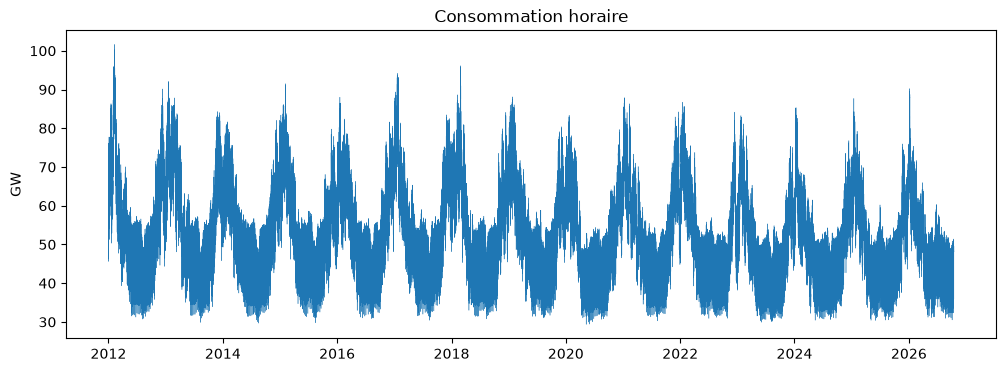

In [20]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(hourly.index, hourly["consommation"] / 1000, linewidth=0.3)
ax.set(title="Consommation horaire", ylabel="GW")
plt.show()

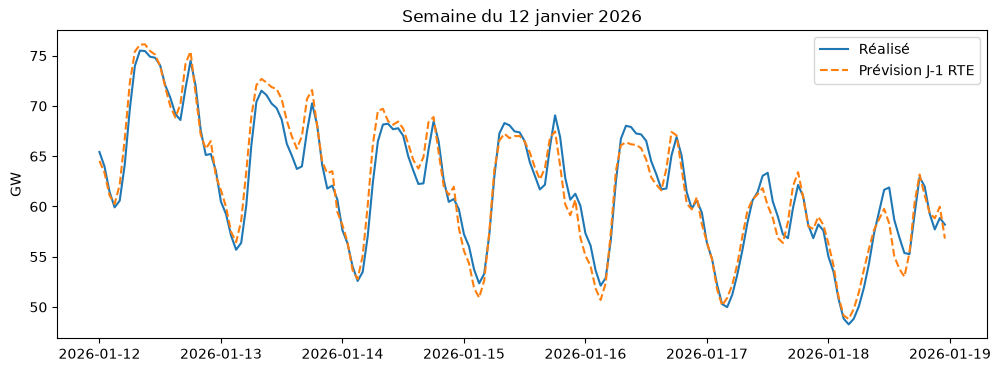

In [22]:
semaine = hourly.loc["2026-01-12":"2026-01-18"]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(semaine.index, semaine["consommation"] / 1000, label="Réalisé")
ax.plot(semaine.index, semaine["prevision_j1"] / 1000, label="Prévision J-1 RTE", linestyle="--")
ax.set(title="Semaine du 12 janvier 2026", ylabel="GW")
ax.legend()
plt.show()

C:\Users\plpbr\AppData\Local\Temp\ipykernel_21544\4192441712.py:1: Pandas4Warning: 'd' is deprecated and will be removed in a future version, please use 'D' instead.
  daily = df[["consommation", "prevision_j1"]].resample("1d").mean()


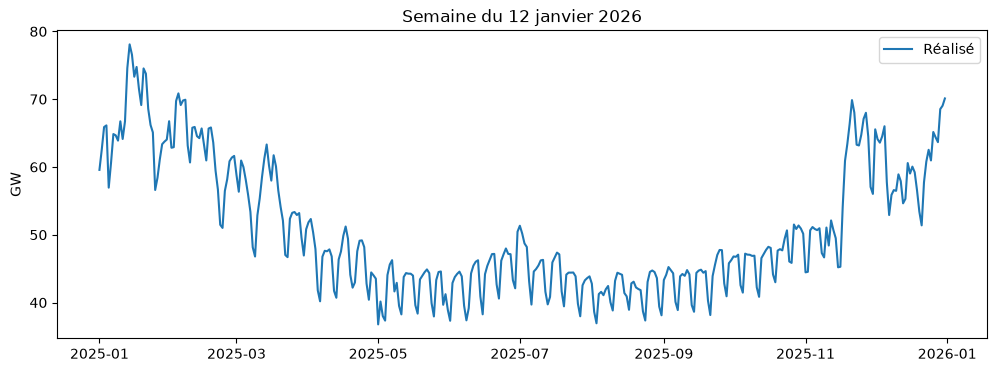

In [25]:
daily = df[["consommation", "prevision_j1"]].resample("1d").mean()
semaine = daily.loc["2025-01-01":"2025-12-31"]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(semaine.index, semaine["consommation"] / 1000, label="Réalisé")
ax.set(title="Semaine du 12 janvier 2026", ylabel="GW")
ax.legend()
plt.show()

## Sauvegarde

In [21]:
out = ROOT / "data/processed/consommation_horaire.parquet"
hourly.to_parquet(out)
print(f"{out.relative_to(ROOT)} : {len(hourly):,} heures, index UTC")

data\processed\consommation_horaire.parquet : 129,638 heures, index UTC
